## Part 1: Data Loading & Initial Inspection

1. Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).

In [130]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import MinMaxScaler , StandardScaler ,LabelEncoder
from imblearn.over_sampling import SMOTE 

2. Load healthcare-dataset-stroke-data.csv into DataFrame df

In [131]:
df=pd.read_csv("healthcare-dataset-stroke-data.csv")


3. Display first 5 rows using df.head()

In [132]:
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


4. Use df.info() to check data types, non-null values, memory usage

In [133]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


5. Use df.describe() for statistical summaries

In [134]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## Part 2: Exploratory Data Analysis & Visualization

1. Create countplot for stroke column (class distribution)

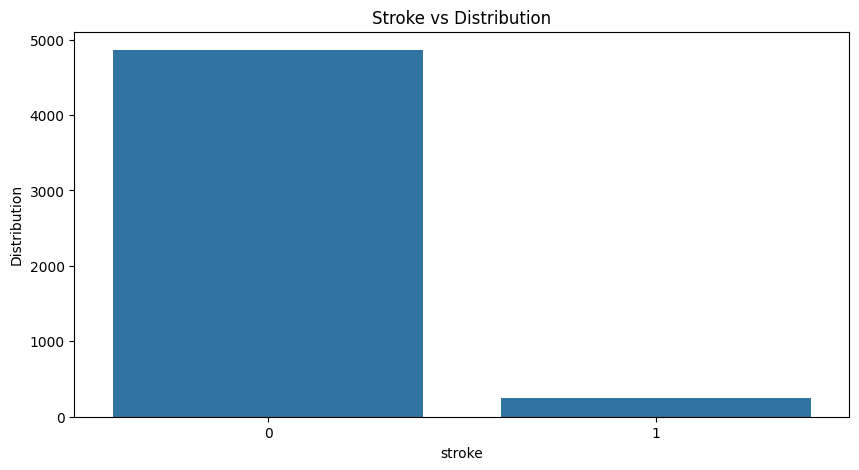

In [135]:
plt.figure(figsize=(10,5))
sns.countplot(data=df , x="stroke")
plt.xlabel("stroke")
plt.ylabel("Distribution")
plt.title("Stroke vs Distribution")
plt.show()

2. Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots

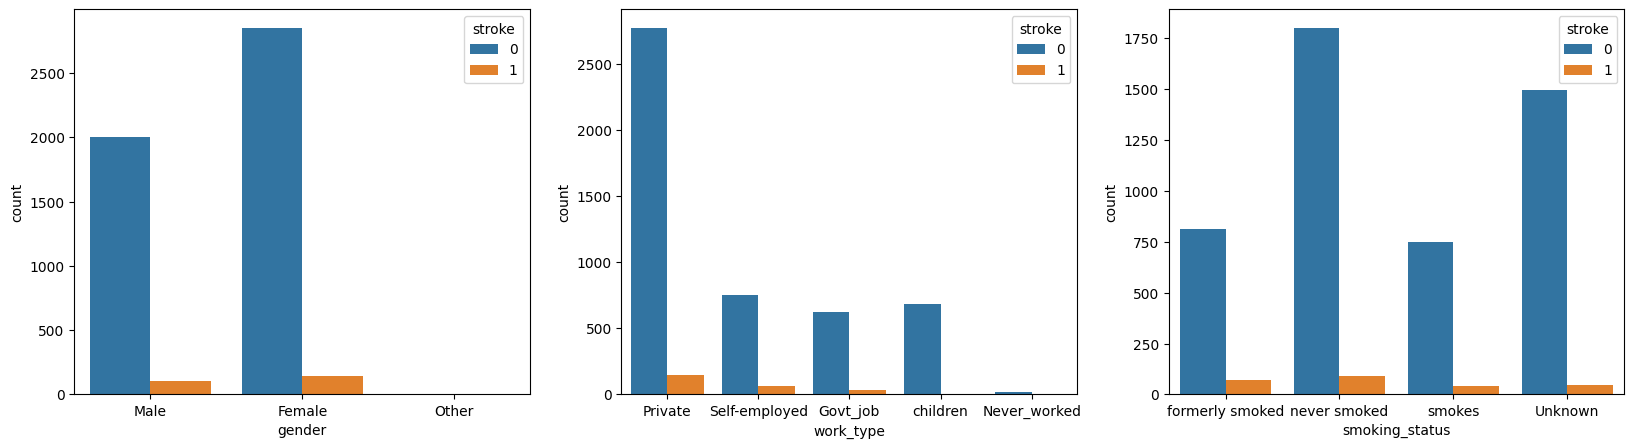

In [136]:
status=["gender","work_type","smoking_status"]
plt.figure(figsize=(20,5))
for i , col in enumerate(status,1):
    plt.subplot(1,3,i)
    sns.countplot(data=df, x=col, hue='stroke')

plt.show()

3. Drop 'Other' gender record (only 1 exists)

In [137]:
df=df[df['gender']!='Other']
df['gender'].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

4. Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots

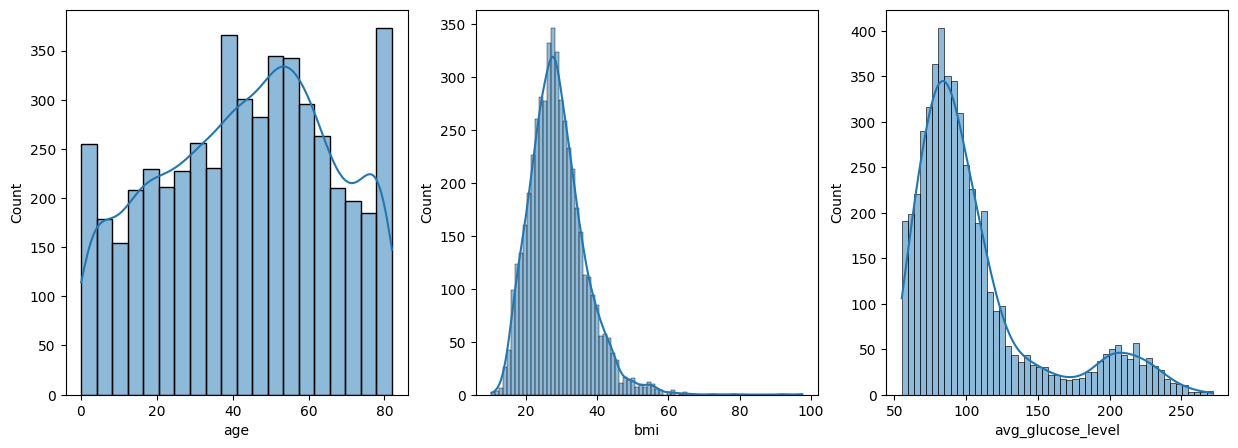

In [138]:
features=['age','bmi','avg_glucose_level']
plt.figure(figsize=(15,5))
for i,col in enumerate(features,1):
    plt.subplot(1,3,i)
    sns.histplot(data=df, x=col, kde=True )

plt.show()

4. Create correlation heatmap using selected numerical features and stroke

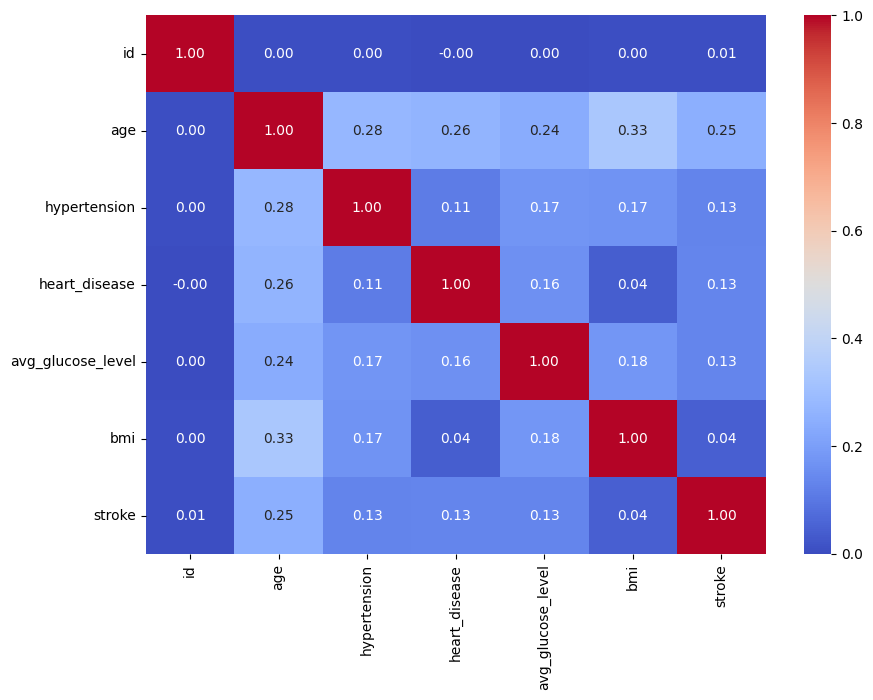

In [139]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(numeric_only=True) ,annot=True ,fmt=".2f" ,cmap="coolwarm")
plt.show()

## Part 3: Data Preprocessing (Cleaning)

1. Check for missing values using df.isnull().sum()

In [140]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

2. Fill bmi missing values using mean or median
3. Verify no missing values remain

In [141]:
df["bmi"]=df["bmi"].fillna(df["bmi"].median())
df.info()

<class 'pandas.DataFrame'>
Index: 5109 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5109 non-null   int64  
 1   gender             5109 non-null   str    
 2   age                5109 non-null   float64
 3   hypertension       5109 non-null   int64  
 4   heart_disease      5109 non-null   int64  
 5   ever_married       5109 non-null   str    
 6   work_type          5109 non-null   str    
 7   Residence_type     5109 non-null   str    
 8   avg_glucose_level  5109 non-null   float64
 9   bmi                5109 non-null   float64
 10  smoking_status     5109 non-null   str    
 11  stroke             5109 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 677.4 KB


4. Check for duplicates and remove them if any exist

In [142]:
(df.duplicated()).sum()

np.int64(0)

5. Drop id column (no predictive power)

In [143]:
df.drop(inplace=True,columns='id')
df.head(5)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


6. Create boxplot for avg_glucose_level to detect outliers and remove if needed

In [144]:
Q1= df["avg_glucose_level"].quantile(.25)
Q2= df["avg_glucose_level"].quantile(.75)
IQR= Q2-Q1

lower=Q1-1.5*IQR
higher=Q2+1.5*IQR
df=df[(df['avg_glucose_level']>=lower) & (df['avg_glucose_level']<=higher)]

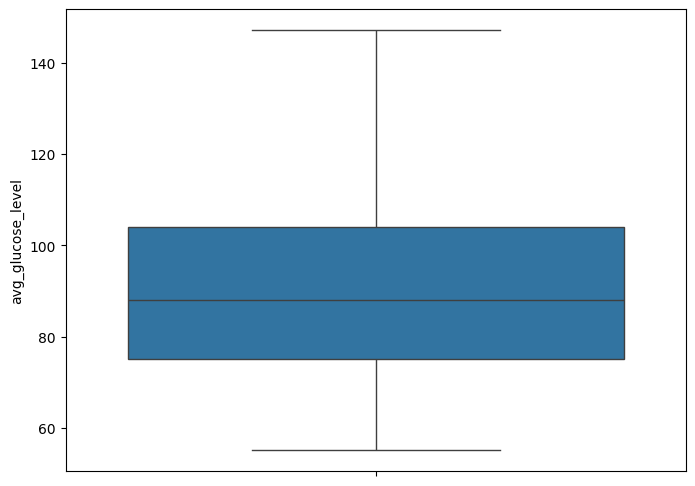

In [145]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, y="avg_glucose_level", showfliers=False )
plt.show()

## Part 4: Feature Transformation

1. Encode categorical variables: gender, work_type, smoking_status, ever_married,
Residence_type

In [146]:
for col in ['gender', 'work_type', 'smoking_status', 'ever_married',
'Residence_type']:
    la=LabelEncoder()
    df[col]=la.fit_transform(df[col])
    
df.head()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2,1,80.0,0,1,1,2,0,105.92,32.5,2,1
6,1,74.0,1,1,1,2,0,70.09,27.4,2,1
7,0,69.0,0,0,0,2,1,94.39,22.8,2,1
8,0,59.0,0,0,1,2,0,76.15,28.1,0,1
9,0,78.0,0,0,1,2,1,58.57,24.2,0,1


2. Reset DataFrame index

In [147]:
df.reset_index(inplace=True, drop=True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,80.0,0,1,1,2,0,105.92,32.5,2,1
1,1,74.0,1,1,1,2,0,70.09,27.4,2,1
2,0,69.0,0,0,0,2,1,94.39,22.8,2,1
3,0,59.0,0,0,1,2,0,76.15,28.1,0,1
4,0,78.0,0,0,1,2,1,58.57,24.2,0,1


3. Apply one-hot encoding using pd.get_dummies() or OneHotEncoder


In [148]:
data=df.copy()
data_onehotencoder=pd.get_dummies(
    data,
    columns=['gender', 'work_type', 'smoking_status', 'ever_married',
'Residence_type'],
    drop_first=True,
    dtype=int
)
data_onehotencoder.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_1,work_type_1,work_type_2,work_type_3,work_type_4,smoking_status_1,smoking_status_2,smoking_status_3,ever_married_1,Residence_type_1
0,80.0,0,1,105.92,32.5,1,1,0,1,0,0,0,1,0,1,0
1,74.0,1,1,70.09,27.4,1,1,0,1,0,0,0,1,0,1,0
2,69.0,0,0,94.39,22.8,1,0,0,1,0,0,0,1,0,0,1
3,59.0,0,0,76.15,28.1,1,0,0,1,0,0,0,0,0,1,0
4,78.0,0,0,58.57,24.2,1,0,0,1,0,0,0,0,0,1,1


In [149]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,80.0,0,1,1,2,0,105.92,32.5,2,1
1,1,74.0,1,1,1,2,0,70.09,27.4,2,1
2,0,69.0,0,0,0,2,1,94.39,22.8,2,1
3,0,59.0,0,0,1,2,0,76.15,28.1,0,1
4,0,78.0,0,0,1,2,1,58.57,24.2,0,1


1. Separate features X and target y

In [150]:
X = df.drop("stroke", axis=1)
y = df["stroke"]

2. Use train_test_split() with 80/20 ratio and random_state=42
3. Verify shapes of X_train, X_test, y_train, y_test

In [152]:
x_train,x_test,y_train,y_test=train_test_split(
    X,y,random_state=42 ,test_size=.2 , stratify=y
    )
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(3585, 10)
(897, 10)
(3585,)
(897,)


2. Scale numerical features: age, avg_glucose_level, bmi
3. Fit scaler on training data only, then transform both train and test sets

In [158]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
standard=StandardScaler()
x_train_scaled=x_train.copy()
x_test_scaled=x_test.copy()

x_train_scaled[num_cols]=standard.fit_transform(x_train[num_cols])
x_test_scaled[num_cols]=standard.transform(x_test[num_cols])

x_train_scaled[num_cols].describe().round(2)

,age,avg_glucose_level,bmi
count,3585.00,3585.00,3585.00
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.82,-1.60,-2.38
25%,-0.79,-0.72,-0.66
50%,0.06,-0.15,-0.07
75%,0.77,0.55,0.51
max,1.84,3.42,9.19


## Part 7: Handling Class Imbalance

1. Check distribution of stroke

In [160]:
y_train.value_counts()

stroke
0    3453
1     132
Name: count, dtype: int64

2. Apply oversampling/undersampling or SMOTE
3. Verify balanced distribution

In [172]:
smote=SMOTE(random_state=42)
x_train_smote,y_train_smote=smote.fit_resample(x_train_scaled,y_train)
print("before"  , y_train.value_counts().sum)
print("-"*30)
print("after", y_train_smote.value_counts().sum)

before <bound method Series.sum of stroke
0    3453
1     132
Name: count, dtype: int64>
------------------------------
after <bound method Series.sum of stroke
0    3453
1    3453
Name: count, dtype: int64>


In [173]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,80.0,0,1,1,2,0,105.92,32.5,2,1
1,1,74.0,1,1,1,2,0,70.09,27.4,2,1
2,0,69.0,0,0,0,2,1,94.39,22.8,2,1
3,0,59.0,0,0,1,2,0,76.15,28.1,0,1
4,0,78.0,0,0,1,2,1,58.57,24.2,0,1


## conclusion
كبار السن (age): السن هو أقوى عامل في الداتا و احتمالية الإصابة بتزيد بشكل واضح جداً فوق سن الـ 60 سنة.

مرضى القلب (heart_disease): وجود تاريخ مع أمراض القلب بيرفع خطر الإصابة بشكل ملحوظ.

مرضى ضغط الدم المرتفع (hypertension): الضغط العالي من أكتر العوامل المرتبطة بحالات الجلطة.

ارتفاع مستوى السكر (avg_glucose_level): الناس اللي متوسط السكر عندهم عالي (مرضى السكر أو ما قبل السكر).

التدخين والوزن الزايد (smoking_status و bmi): اللي بيدخّنوا أو كانوا بيدخّنوا قبل كده، خصوصاً لو معاه وزن زايد.